# 10. 消融实验 (v2 含 σ_t)
诊断型消融实验：从窗口长度和分布偏移两个维度解释预测精度受限的原因。

In [ ]:
import os, copy, random, warnings
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', font_scale=1.1)
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

C_BL, C_MN = '#8DB4D8', '#F2B872'  # 与 notebook 7 消融图配色一致
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

DATA_PATH = '../data/04_final_feature_matrix_v2.csv'
RESULT_DIR = '../results/'
SUMMARY = pd.read_csv(os.path.join(RESULT_DIR, 'search4.0_global_summary_metrics.csv'))
best_row = SUMMARY[(SUMMARY['Model']=='Main') & (SUMMARY['Feature_Group']=='G3')].iloc[0]
BEST_P = {
    'hidden_size': int(best_row['Best_Hidden']),
    'dropout': best_row['Best_Dropout'],
    'batch_size': int(best_row['Best_BatchSize']),
    'lr': best_row['Best_LR'],
    'weight_decay': best_row['Best_WD']
}
print(f'Device: {device}')
print(f'Main×G3 最优参数: {BEST_P}')

Device: cuda
Main×G3 最优参数: {'hidden_size': 256, 'dropout': 0.2587, 'batch_size': 64, 'lr': 0.00327, 'weight_decay': 1e-05}


In [2]:
class DS(Dataset):
    def __init__(self, f, t, w): self.f, self.t, self.w = f, t, w
    def __len__(self): return len(self.f)-self.w+1
    def __getitem__(self, i): return torch.FloatTensor(self.f[i:i+self.w]), torch.FloatTensor([self.t[i+self.w-1]])

class BiLSTMAttention(nn.Module):
    def __init__(self, inp, hid, dp):
        super().__init__()
        self.bilstm = nn.LSTM(inp, hid, 1, batch_first=True, bidirectional=True)
        self.attn_w = nn.Linear(hid*2, 1, bias=False)
        self.dropout = nn.Dropout(dp)
        self.fc = nn.Sequential(nn.Linear(hid*2, 32), nn.ReLU(), nn.Linear(32, 1))
    def forward(self, x):
        o, _ = self.bilstm(x)
        a = F.softmax(self.attn_w(o), dim=1)
        c = torch.sum(a * o, dim=1)
        return self.fc(self.dropout(c)), a.squeeze(-1)

def run_exp(lb, f_tr, t_tr, f_va, t_va, f_te, t_te, dim):
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    tr_ds, va_ds, te_ds = DS(f_tr, t_tr, lb), DS(f_va, t_va, lb), DS(f_te, t_te, lb)
    tl = DataLoader(tr_ds, BEST_P['batch_size'], True)
    vl = DataLoader(va_ds, BEST_P['batch_size'])
    tel = DataLoader(te_ds, BEST_P['batch_size'])
    m = BiLSTMAttention(dim, BEST_P['hidden_size'], BEST_P['dropout']).to(device)
    crit = nn.MSELoss()
    opt = torch.optim.AdamW(m.parameters(), lr=BEST_P['lr'], weight_decay=BEST_P['weight_decay'])
    sch = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, 'min', factor=0.5, patience=7)
    best_v, best_w, no_imp = float('inf'), None, 0
    for _ in range(300):
        m.train()
        for xb, yb in tl: opt.zero_grad(); p, _ = m(xb.to(device)); crit(p, yb.to(device)).backward(); opt.step()
        m.eval(); vls = []
        with torch.no_grad():
            for xv, yv in vl: p, _ = m(xv.to(device)); vls.append(crit(p, yv.to(device)).item())
        av = np.mean(vls); sch.step(av)
        if av < best_v: best_v = av; best_w = copy.deepcopy(m.state_dict()); no_imp = 0
        else: no_imp += 1
        if no_imp >= 20: break
    m.load_state_dict(best_w); m.eval(); ps, ts = [], []
    with torch.no_grad():
        for xt, yt in tel: p, _ = m(xt.to(device)); ps.extend(p.cpu().numpy()); ts.extend(yt.numpy())
    ps, ts = np.array(ps).flatten(), np.array(ts).flatten()
    return np.sqrt(mean_squared_error(ts, ps)), r2_score(ts, ps)

## 消融实验一：滑动窗口长度

In [3]:
df = pd.read_csv(DATA_PATH)
cols = [c for c in df.columns if c not in ['timestamp','target_sigma_t_plus_1','finbert_sentiment_score','llm_composite_score','sentiment_class','action_class','action_score']]
f_cols = cols + ['llm_composite_score']  # G3 特征组
te_idx, ve_idx = int(len(df)*0.7), int(len(df)*0.8)
f_tr, t_tr = df.iloc[:te_idx][f_cols].values, df.iloc[:te_idx]['target_sigma_t_plus_1'].values
f_va, t_va = df.iloc[te_idx:ve_idx][f_cols].values, df.iloc[te_idx:ve_idx]['target_sigma_t_plus_1'].values
f_te, t_te = df.iloc[ve_idx:][f_cols].values, df.iloc[ve_idx:]['target_sigma_t_plus_1'].values

lbs = [3, 5, 7, 10, 14]
res = []
for l in lbs:
    print(f'Lookback={l} 训练中...', end='', flush=True)
    rmse, r2 = run_exp(l, f_tr, t_tr, f_va, t_va, f_te, t_te, len(f_cols))
    res.append({'Lookback': l, 'RMSE': rmse, 'R2': r2})
    print(f' RMSE={rmse:.4f}, R2={r2:.4f}')

df_res = pd.DataFrame(res)
df_res.to_csv(os.path.join(RESULT_DIR, 'ablation_v2_results.csv'), index=False)
display(df_res.round(4))

Lookback=3 训练中...

 RMSE=1.4531, R2=-0.1361
Lookback=5 训练中...

 RMSE=1.4170, R2=-0.0773
Lookback=7 训练中...

 RMSE=1.2879, R2=0.1136
Lookback=10 训练中...

 RMSE=1.3230, R2=0.0686
Lookback=14 训练中...

 RMSE=1.4334, R2=-0.0932


,Lookback,RMSE,R2
0,3,1.4531,-0.1361
1,5,1.4170,-0.0773
2,7,1.2879,0.1136
3,10,1.3230,0.0686
4,14,1.4334,-0.0932


## 消融实验一可视化：Lookback vs RMSE（含均值基线）

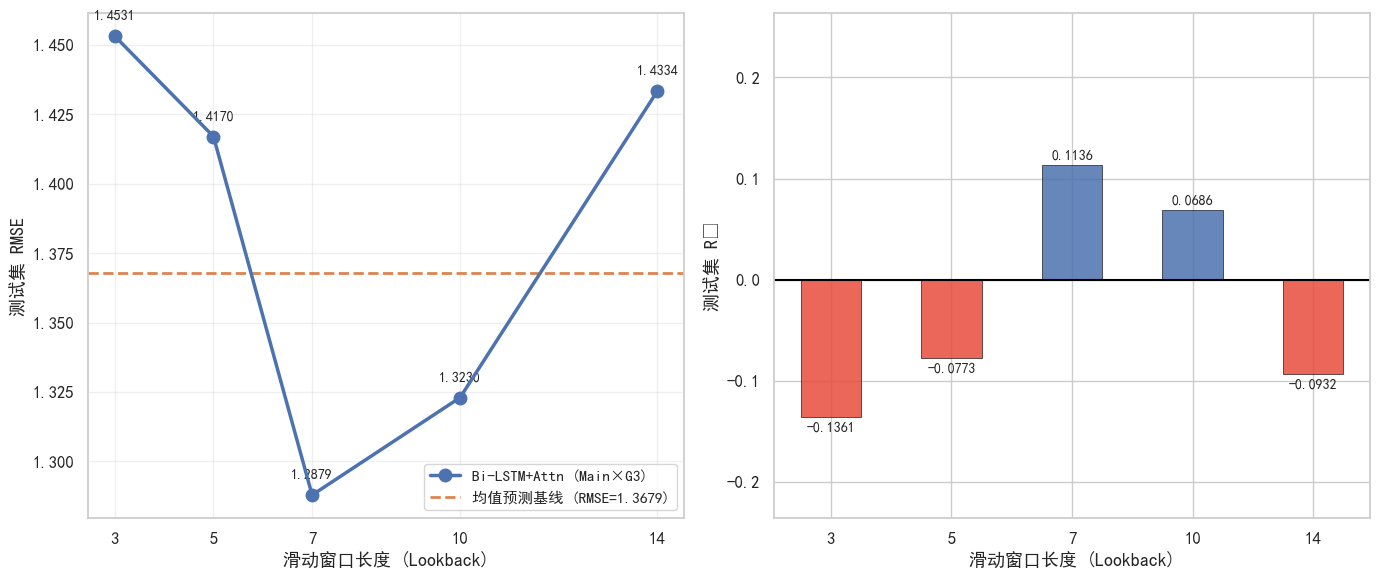


均值预测基线 RMSE: 1.3679
Lookback=7 RMSE: 1.2879
Lookback=7 相对基线改善: 5.85%


In [ ]:
# 计算均值预测基线 RMSE（以 lookback=7 的测试样本为准）
test_targets = t_te[7-1:]
mean_baseline_rmse = np.sqrt(np.mean((test_targets - test_targets.mean())**2))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 左图：RMSE
axes[0].plot(df_res['Lookback'], df_res['RMSE'], 'o-', color=C_BL, linewidth=2.5, markersize=9, zorder=5, label='Bi-LSTM+Attn (Main×G3)')
axes[0].axhline(y=mean_baseline_rmse, color=C_MN, linestyle='--', linewidth=2, label=f'均值预测基线 (RMSE={mean_baseline_rmse:.4f})')
# 标注每个点的数值
for _, r in df_res.iterrows():
    axes[0].annotate(f"{r['RMSE']:.4f}", (r['Lookback'], r['RMSE']), textcoords='offset points', xytext=(0, 12), ha='center', fontsize=10)
axes[0].set_xlabel('滑动窗口长度 (Lookback)', fontsize=13)
axes[0].set_ylabel('测试集 RMSE', fontsize=13)
axes[0].set_xticks(lbs); axes[0].legend(fontsize=11); axes[0].grid(True, alpha=0.3)

# 右图：R²
bar_colors = [C_BL if r >= 0 else '#E74C3C' for r in df_res['R2']]
b = axes[1].bar(df_res['Lookback'].astype(str), df_res['R2'], color=bar_colors, alpha=0.85, edgecolor='black', linewidth=0.5, width=0.5)
axes[1].bar_label(b, padding=3, fmt='%.4f', fontsize=10)
axes[1].axhline(y=0, color='black', linewidth=1.5, linestyle='-')
axes[1].set_xlabel('滑动窗口长度 (Lookback)', fontsize=13)
axes[1].set_ylabel('测试集决定系数（R2）', fontsize=13)
axes[1].set_ylim(min(df_res['R2'])-0.1, max(df_res['R2'])+0.15)

plt.tight_layout()
plt.savefig(os.path.join(RESULT_DIR, 'ablation_lookback_v2.png'), dpi=300, bbox_inches='tight')
plt.show()
print(f'\n均值预测基线 RMSE: {mean_baseline_rmse:.4f}')
print(f'Lookback=7 RMSE: {df_res[df_res["Lookback"]==7]["RMSE"].values[0]:.4f}')
print(f'Lookback=7 相对基线改善: {(mean_baseline_rmse - df_res[df_res["Lookback"]==7]["RMSE"].values[0])/mean_baseline_rmse*100:.2f}%')

## 消融分析二：训练集 vs 测试集分布偏移诊断

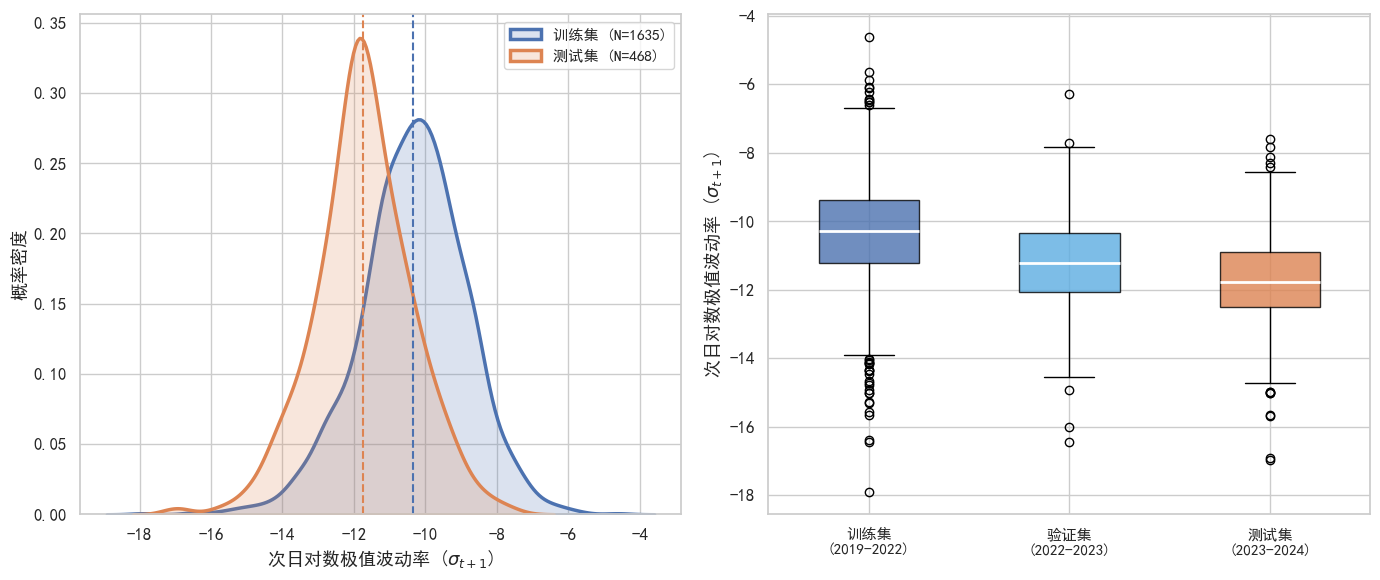

=== 各数据集统计量 ===
训练集: N=1635, Mean=-10.3534, Std=1.4954, Min=-17.8925, Max=-4.6174
验证集: N=233, Mean=-11.2438, Std=1.4147, Min=-16.4428, Max=-6.2877
测试集: N=468, Mean=-11.7433, Std=1.3637, Min=-16.9714, Max=-7.6066

分布偏移量 (均值偏移 / 训练集标准差): -0.9294 σ


In [5]:
train_sigma = df.iloc[:te_idx]['target_sigma_t_plus_1'].values
val_sigma   = df.iloc[te_idx:ve_idx]['target_sigma_t_plus_1'].values
test_sigma  = df.iloc[ve_idx:]['target_sigma_t_plus_1'].values

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 左图：KDE分布对比
sns.kdeplot(train_sigma, ax=axes[0], color=C_BL, linewidth=2.5, label=f'训练集 (N={len(train_sigma)})', fill=True, alpha=0.2)
sns.kdeplot(test_sigma,  ax=axes[0], color=C_MN, linewidth=2.5, label=f'测试集 (N={len(test_sigma)})', fill=True, alpha=0.2)
axes[0].axvline(train_sigma.mean(), color=C_BL, linestyle='--', linewidth=1.5)
axes[0].axvline(test_sigma.mean(),  color=C_MN, linestyle='--', linewidth=1.5)
axes[0].set_xlabel('次日对数极值波动率（预测目标变量）', fontsize=13)
axes[0].set_ylabel('概率密度', fontsize=13)
axes[0].legend(fontsize=11)

# 右图：箱线图对比
data_box = [train_sigma, val_sigma, test_sigma]
bp = axes[1].boxplot(data_box, patch_artist=True, widths=0.5,
                     medianprops=dict(color='white', linewidth=2))
bp_colors = [C_BL, '#5DADE2', C_MN]
for patch, color in zip(bp['boxes'], bp_colors):
    patch.set_facecolor(color); patch.set_alpha(0.55); patch.set_edgecolor('#9CA3AF')
axes[1].set_xticks([1, 2, 3])
axes[1].set_xticklabels(['训练集\n(2018–2022)', '验证集\n(2022–2023)', '测试集\n(2023–2024)'], fontsize=11)
axes[1].set_ylabel('次日对数极值波动率（预测目标变量）', fontsize=13)

plt.tight_layout()
plt.savefig(os.path.join(RESULT_DIR, 'ablation_distribution_shift.png'), dpi=300, bbox_inches='tight')
plt.show()

# 打印统计量
print('=== 各数据集统计量 ===')
for name, data in [('训练集', train_sigma), ('验证集', val_sigma), ('测试集', test_sigma)]:
    print(f'{name}: N={len(data)}, Mean={data.mean():.4f}, Std={data.std():.4f}, Min={data.min():.4f}, Max={data.max():.4f}')

shift = (test_sigma.mean() - train_sigma.mean()) / train_sigma.std()
print(f'\n分布偏移量 (均值偏移 / 训练集标准差): {shift:.4f} σ')